# 01 · Populations, samples, and variation

A mean tells us where observations balance; a standard deviation tells us how widely they vary. When we observe only a sample, both are estimates. Understanding the difference between the spread of observations and the uncertainty of an estimate is the foundation of inference.

```mermaid
flowchart TD
    A[Define units and population] --> B[Identify variable types]
    B --> C[Describe center and spread]
    C --> D[Population parameters versus sample statistics]
    D --> E[Why divide by n minus 1?]
    E --> F[Sampling variability and standard error]
```

**Learning route:** data types → descriptive summaries → estimation → uncertainty. Prerequisites: sums, squares, and square roots; see [AA](../AA_Prerequisite/AA_Prerequisite.md).

## 1. What is one observation?

Suppose we measure the mass of notebooks packed by a small stationery workshop. The observational unit is one notebook, the numerical variable is mass in grams, and the target population might be all notebooks made by the workshop this week. “All notebooks everywhere” is a different population and is not represented merely by collecting more measurements at one workshop.

A variable can be **categorical** (cover color, with no numerical spacing), **ordinal** (a quality rating whose order is meaningful), or **quantitative**. Quantitative variables can be **discrete**, such as the number of torn pages, or **continuous**, such as underlying mass. A rounded mass measurement remains a measurement of a continuous quantity. Numerical labels such as product codes are not quantities to average.

Dependence matters too. Measuring the same notebook ten times gives information about instrument repeatability, but not ten independent notebooks' worth of information about production variability. Always count the units relevant to the question.

## 2. Center: mean and median answer different questions

For observations $x_1,\ldots,x_n$, the arithmetic mean is

$$\bar x=\frac{1}{n}\sum_{i=1}^{n}x_i.$$

The **median** splits ordered data into two halves; for even $n$, the usual sample median averages the middle two values. The mean uses the magnitude of every observation. The median depends primarily on order and is less sensitive to an extreme observation.

Use these invented masses: **96, 98, 100, 102, 104 grams**. Their sum is 500, mean is 100, and median is 100. Replacing 104 by 144 increases the mean to 108 but leaves the median at 100. The arithmetic is correct in both cases. The question is which summary communicates the feature you care about. If total material consumption matters, the mean is directly useful; if a typical notebook matters, the median may be more representative under skewness.

The mean minimizes $\sum_i(x_i-a)^2$ over choices of center $a$. A median minimizes $\sum_i|x_i-a|$. Different loss functions explain their different responses to extreme observations.

## 3. Spread: calculate variance step by step

For the five original masses, deviations from the mean are $-4,-2,0,2,4$. Their sum is zero, so averaging signed deviations cannot measure spread. Squaring makes all deviations nonnegative and emphasizes larger deviations.

| Mass $x_i$ | Deviation $x_i-100$ | Squared deviation |
|---:|---:|---:|
| 96 | -4 | 16 |
| 98 | -2 | 4 |
| 100 | 0 | 0 |
| 102 | 2 | 4 |
| 104 | 4 | 16 |
| **Total** | **0** | **40** |

If these five notebooks are the **entire finite population of interest**, its variance is $40/5=8\text{ g}^2$, and its standard deviation is $\sqrt8\approx2.828$ grams. More generally,

$$\mu=\frac{1}{N}\sum_{i=1}^N x_i,\qquad
\sigma_{\mathrm{finite}}^2=\frac{1}{N}\sum_{i=1}^N(x_i-\mu)^2.$$

If instead the five observations are an independent sample from an ongoing process with variance $\sigma^2$, the usual unbiased variance estimator is

$$s^2=\frac{\sum_i(x_i-\bar x)^2}{n-1}=\frac{40}{4}=10\text{ g}^2,
\qquad s=\sqrt{10}\approx3.162\text{ g}.$$

Variance has squared units; standard deviation returns to the original units. Neither is the average absolute deviation. In NumPy, `np.var(x, ddof=0)` divides by $n$ and `np.var(x, ddof=1)` divides by $n-1$. Specify the denominator deliberately.

![Mass deviations and the effect of an unusual observation](figure/center_spread.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '01_Fundamental_Concepts_in_Statistics' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


,mass_g,deviation_g,squared_g2
0,96.0,-4.0,16.0
1,98.0,-2.0,4.0
2,100.0,0.0,0.0
3,102.0,2.0,4.0
4,104.0,4.0,16.0


Mean=100.000; population descriptive variance=8.000
Sample variance=10.000; sample SD=3.162


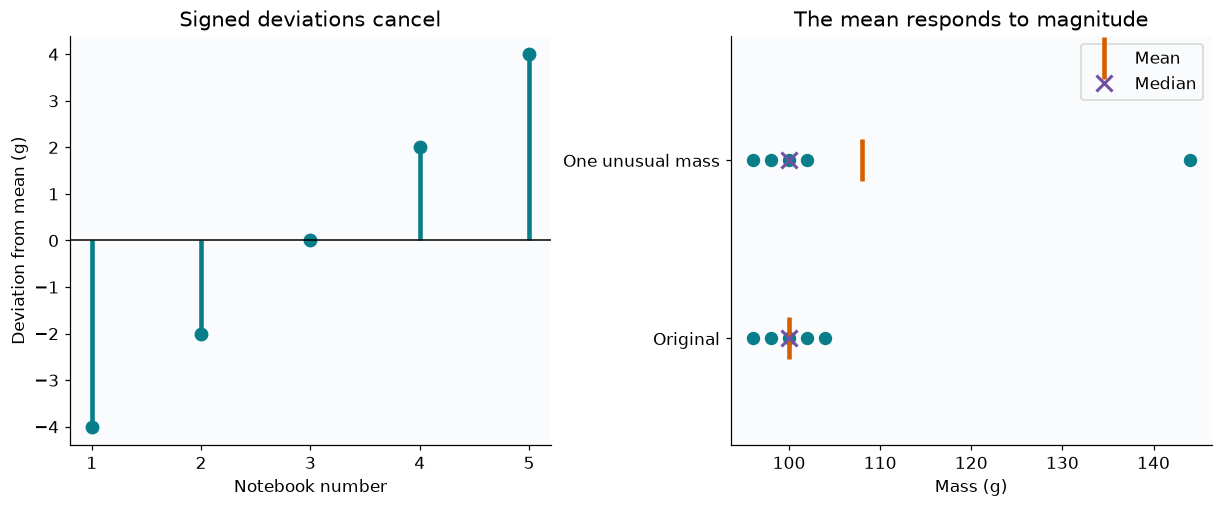

In [2]:
x = np.array([96, 98, 100, 102, 104], dtype=float)
deviations = x - x.mean()
display(pd.DataFrame({"mass_g": x, "deviation_g": deviations, "squared_g2": deviations**2}))
print(f"Mean={x.mean():.3f}; population descriptive variance={x.var(ddof=0):.3f}")
print(f"Sample variance={x.var(ddof=1):.3f}; sample SD={x.std(ddof=1):.3f}")
assert np.isclose(np.sum(deviations**2), 40)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
axes[0].vlines(np.arange(1, 6), 0, deviations, color=TEAL, lw=3)
axes[0].scatter(np.arange(1, 6), deviations, color=TEAL, s=65)
axes[0].axhline(0, color="black", lw=1)
axes[0].set(xlabel="Notebook number", ylabel="Deviation from mean (g)", title="Signed deviations cancel", xticks=np.arange(1, 6))
for row, values in enumerate([x, np.array([96, 98, 100, 102, 144])]):
    axes[1].scatter(values, np.full(5, row), s=60, color=TEAL)
    axes[1].plot(values.mean(), row, "|", ms=28, mew=3, color=ORANGE, label="Mean" if row == 0 else None)
    axes[1].plot(np.median(values), row, "x", ms=10, mew=2, color=PURPLE, label="Median" if row == 0 else None)
axes[1].set(xlabel="Mass (g)", yticks=[0, 1], yticklabels=["Original", "One unusual mass"], ylim=(-.6, 1.7), title="The mean responds to magnitude")
axes[1].legend(loc="upper right")
save_figure(fig, "center_spread")

## 4. Why $n-1$? A derivation, not a rule to memorize

Assume $X_1,\ldots,X_n$ are independent and identically distributed, with mean $\mu$ and finite variance $\sigma^2$. The sample mean is fitted to these same observations, making their squared distances from it systematically smaller than their squared distances from the unknown population mean. Algebra gives

$$\sum_i(X_i-\bar X)^2
=\sum_i(X_i-\mu)^2-n(\bar X-\mu)^2.$$

To see why the cross-term disappears, expand $X_i-\mu=(X_i-\bar X)+(\bar X-\mu)$ and use $\sum_i(X_i-\bar X)=0$.

Taking expectations, the first sum has expectation $n\sigma^2$. Independence implies $\operatorname{Var}(\bar X)=\sigma^2/n$, so the final term has expectation $n(\sigma^2/n)=\sigma^2$. Consequently,

$$E\!\left[\sum_i(X_i-\bar X)^2\right]=(n-1)\sigma^2.$$

Dividing by $n-1$ therefore gives $E[s^2]=\sigma^2$. Dividing by $n$ has expectation $(n-1)\sigma^2/n$. With $n=5$, it averages only 80% of the true variance.

Another view is **degrees of freedom**: after fixing the mean, the deviations must sum to zero, so the last deviation is determined by the others. This explains the one fitted constraint; the expectation calculation establishes unbiasedness. Unbiased means correct **on average over repeated samples**, not correct in every sample. Also, $\sqrt{s^2}$ is generally not an unbiased estimator of $\sigma$ because taking a square root is nonlinear.

![Bias of two variance estimators over repeated samples](figure/variance_estimators.png)

**Notebook experiment:** sample five observations repeatedly from a normal process with standard deviation 4 grams. Compare the average of the two variance estimators with $\sigma^2=16$. Change $n$ to 20. The bias of division by $n$ shrinks, while both estimators become more stable.

Average with n: 12.890; target 12.800
Average with n-1: 16.112; target 16.000


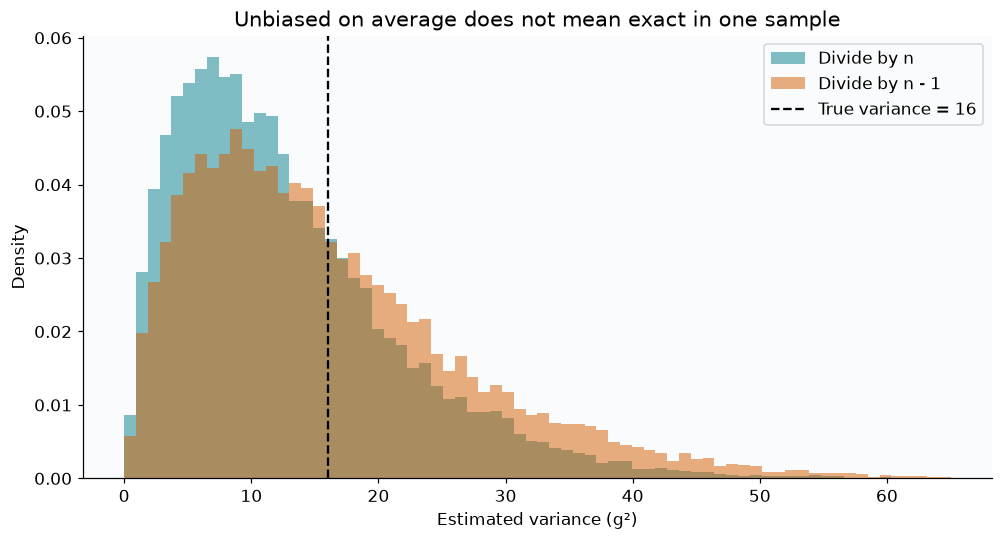

In [3]:
rng = np.random.default_rng(101)
n, repetitions, sigma = 5, 20000, 4
samples = rng.normal(100, sigma, size=(repetitions, n))
v_n = samples.var(axis=1, ddof=0)
v_corrected = samples.var(axis=1, ddof=1)
print(f"Average with n: {v_n.mean():.3f}; target {(n-1)/n*sigma**2:.3f}")
print(f"Average with n-1: {v_corrected.mean():.3f}; target {sigma**2:.3f}")
fig, ax = plt.subplots(layout="constrained")
ax.hist(v_n, bins=70, range=(0, 65), density=True, alpha=.5, label="Divide by n")
ax.hist(v_corrected, bins=70, range=(0, 65), density=True, alpha=.5, label="Divide by n - 1")
ax.axvline(sigma**2, color="black", ls="--", label="True variance = 16")
ax.set(xlabel="Estimated variance (g²)", ylabel="Density", title="Unbiased on average does not mean exact in one sample")
ax.legend()
save_figure(fig, "variance_estimators")

## 5. Standard deviation is not standard error

The **standard error** of a statistic is the standard deviation of its sampling distribution. For the mean of iid observations,

$$\operatorname{SE}(\bar X)=\frac{\sigma}{\sqrt n},\qquad
\widehat{\operatorname{SE}}(\bar X)=\frac{s}{\sqrt n}.$$

SD answers “How variable are individual notebook masses?” SE answers “How variable would the sample mean be across repeated samples?” For our five masses, the estimated SE is $\sqrt{10}/\sqrt5=\sqrt2\approx1.414$ grams. This is not the spread of the five individual masses.

If $n$ increases fourfold under the same iid process, the SE halves. Individual variability $\sigma$ stays the same. To improve the variability of the products themselves, we need to change the production process, not simply measure more products.

![Individual measurements versus averages](figure/sd_vs_se.png)

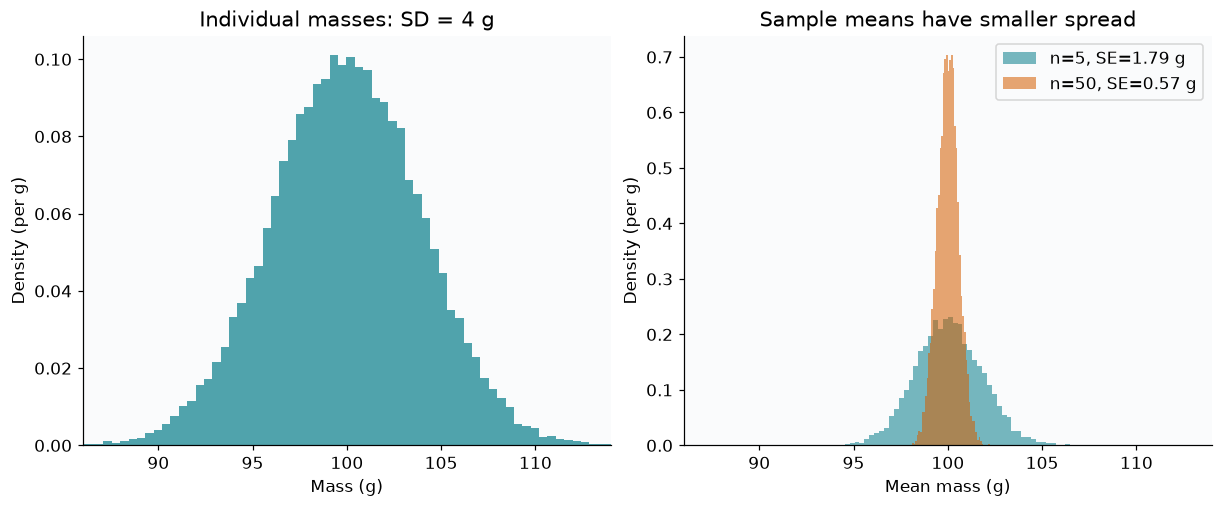

In [4]:
rng = np.random.default_rng(102)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
individuals = rng.normal(100, 4, 30000)
axes[0].hist(individuals, bins=65, density=True, color=TEAL, alpha=.7)
axes[0].set(title="Individual masses: SD = 4 g", xlabel="Mass (g)", ylabel="Density (per g)")
for size in [5, 50]:
    means = rng.normal(100, 4, (8000, size)).mean(axis=1)
    axes[1].hist(means, bins=50, density=True, alpha=.55, label=f"n={size}, SE={4/np.sqrt(size):.2f} g")
axes[1].set(title="Sample means have smaller spread", xlabel="Mean mass (g)", ylabel="Density (per g)")
axes[1].legend()
for ax in axes:
    ax.set_xlim(86, 114)
save_figure(fig, "sd_vs_se")

Sampling without replacement from a small finite population needs extra care. If $S^2=\sum(x_i-\mu)^2/(N-1)$ denotes the finite-population variance with denominator $N-1$, simple random sampling gives $\operatorname{Var}(\bar X)=(1-n/N)S^2/n$. The factor accounts for learning more as a sample approaches a census. The iid formulas in this course concern a continuing process or a negligible sampling fraction unless stated otherwise.

## 6. What summaries leave out

Two datasets can have the same mean and SD but different shapes, clusters, or outliers. Plot the individual data when $n$ is small and a histogram when it is large. For strongly skewed data, report the median and interquartile range, $IQR=Q_3-Q_1$, alongside a graph. Software packages use different interpolation conventions for sample quantiles, so record the method if exact reproduction matters.

The familiar statement “about 95% of observations lie within two SDs of the mean” is an approximate **normal-distribution** statement. It is not a universal consequence of computing an SD. A census removes sampling uncertainty about its own measured values; it does not remove measurement error or uncertainty about future production.

## 7. Practice

1. A sample of cable lengths is 8, 10, 10, 12 cm. Calculate mean, median, sample variance, sample SD, and estimated SE of the mean.
2. Every cable length is multiplied by 10 to convert to millimeters. What happens to variance and SD?
3. Explain why $n=1$ cannot estimate an unknown population variance using $s^2$.
4. You measure five devices 100 times each. Can you use $n=500$ in the iid SE formula to describe variation among devices?
5. A normal process has variance 25. What is the expected value of the variance estimator that divides by $n$ for $n=10$?

## 8. Worked answers

1. Mean and median are 10 cm. Squared deviations sum to 8, so $s^2=8/3\approx2.667\text{ cm}^2$, $s\approx1.633$ cm, and estimated SE is $1.633/2\approx0.816$ cm.
2. Variance is multiplied by $10^2=100$; SD is multiplied by 10. Adding a constant instead would change the mean but leave variance and SD unchanged.
3. The single observation equals its sample mean. There is no remaining deviation with which to estimate variability, and the denominator is zero.
4. No. Repeated measurements within a device are dependent for that question. A design or model must distinguish between-device variation from within-device measurement noise.
5. $(9/10)25=22.5$. This is an expectation over repetitions, not a claim that every estimated variance is 22.5.

In [5]:
cables = np.array([8, 10, 10, 12], dtype=float)
assert np.isclose(cables.var(ddof=1), 8/3)
assert np.isclose((10*cables).var(ddof=1), 100*cables.var(ddof=1))
print({"mean": cables.mean(), "median": np.median(cables),
       "sample_variance": cables.var(ddof=1), "sample_sd": cables.std(ddof=1),
       "estimated_se": stats.sem(cables)})

{'mean': np.float64(10.0), 'median': np.float64(10.0), 'sample_variance': np.float64(2.6666666666666665), 'sample_sd': np.float64(1.632993161855452), 'estimated_se': np.float64(0.816496580927726)}


## References and next step

Reading connection: Starmer (2026), Chapter 1, [SQ](../Reference.md#sq-statquest). Formal variance and uncertainty definitions are supported by [NIST's measures of scale](https://www.itl.nist.gov/div898/handbook/eda/section3/eda356.htm) and [confidence limits](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm). The derivation and simulations here are original.

Next: [02 · Histograms](../02_Histogram/02_Histogram.md).